# Water solubility in mineral lubricating oils
**Experimental evidence, NeqSim CPA/SRK calculations, and cooling-induced water separation**  
Version 1.0.0 · 12 October 2026 · pressure is absolute · concentration is mg/kg (ppmw).

This study compares two historical mineral-oil datasets and a formulated engine-oil comparator,
then studies four explicitly assumed mineral-oil pseudo-component cases. Learn to calculate
water saturation with NeqSim, assess model error, separate calibration from validation, and
estimate water release during cooling. All tables and plots below contain executed results.

**Scope:** equilibrium dissolved water, not emulsion stability, lubricant wear or removal kinetics.
No proprietary product formulations are inferred. Viscosity grade alone cannot define an oil EOS.

## 1. Experimental sources and evidence quality

| Dataset | Evidence used | Treatment |
|---|---|---|
| Groschuff paraffin oil (1911), reproduced by Hibbard–Schalla | Six square experimental markers in NACA RM E52D24, Fig. 4(a), printed p. 22 | Manual digitization; ±2 °C and ±8% reading envelopes, **not** reported measurement uncertainty; MW and density unknown |
| Griswold–Kasch lubricating oil (1942), reproduced by Hibbard–Schalla | All 16 experimental rows in NACA Table III, printed p. 13 | Exact table transcription; estimated MW 425 g/mol, H/C mass ratio 0.151, API gravity 29.3 |
| Al Sheikh Omar et al. formulated 15W-40 oil (2024) | Table 2: final four stabilized KF readings at 20, 40, 60 °C | Average those readings; retained individual reported standard deviations; chemical base-oil identity is not established here |

Sources: [NACA report, public US-government archive](https://ntrs.nasa.gov/api/citations/19930087220/downloads/19930087220.pdf),
[original Griswold–Kasch paper](https://doi.org/10.1021/ie50391a007),
[2024 open-access engine-oil paper](https://doi.org/10.1007/s11249-024-01876-y),
[Table 2](https://link.springer.com/article/10.1007/s11249-024-01876-y/tables/2).
The historical measurements are accessed through the NACA reproduction, not a new experiment.
No points calculated from a correlation are labelled experimental.

The formulated-oil comparison uses the authors' operational saturation method. KF can include
water held by additives or fine dispersed structures; it does not by itself establish the molecular
solubility represented by a hydrocarbon EOS. Its results must not be transferred to neat mineral oils.

## 2. Clean Colab setup and immutable NeqSim source
The demonstration uses the NeqSim master commit resolved on 12 October 2026. The Python
package supplies JPype; the **Java calculations load the source-built JAR**. A fresh Colab
runtime needs Java, git, and internet access for this setup. Local validation can supply
`NEQSIM_SOURCE_ROOT` and `NEQSIM_SOURCE_JAR` for the same pinned source.

In [1]:
import importlib.util
import subprocess
import sys

packages = {
    'neqsim': 'neqsim==3.24.0',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'scipy': 'scipy',
}
missing = [requirement for module, requirement in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Python dependencies available.')

Python dependencies available.


In [2]:
import hashlib
import importlib.metadata
import os
from pathlib import Path
import platform

NEQSIM_SOURCE_REF = '9b1366b6d3f3a8f1b170fbd0c623692fa5252a1a'
os.environ['NEQSIM_JVM_AUTOSTART'] = '0'
source_root = Path(os.environ.get('NEQSIM_SOURCE_ROOT', '/content/neqsim-source'))
if not (source_root / '.git').exists():
    subprocess.check_call([
        'git', 'clone', 'https://github.com/equinor/neqsim.git', str(source_root),
    ])
    subprocess.check_call(['git', 'checkout', NEQSIM_SOURCE_REF], cwd=source_root)
resolved_commit = subprocess.check_output(
    ['git', 'rev-parse', 'HEAD'], cwd=source_root, text=True,
).strip()
assert resolved_commit == NEQSIM_SOURCE_REF, 'Source checkout does not match pinned master.'
if 'NEQSIM_SOURCE_JAR' in os.environ:
    source_jar = Path(os.environ['NEQSIM_SOURCE_JAR']).resolve()
else:
    subprocess.check_call([
        'bash', 'mvnw', '-q', '-DskipTests', '-Dmaven.javadoc.skip=true', 'package',
    ], cwd=source_root)
    source_jar = (source_root / 'target/neqsim-3.24.0.jar').resolve()
jar_sha256 = hashlib.sha256(source_jar.read_bytes()).hexdigest()

import jpype

assert not jpype.isJVMStarted(), 'Restart the runtime before changing NeqSim JARs.'
jpype.addClassPath(str(source_jar))
jpype.startJVM(convertStrings=True)
CPA = jpype.JClass('neqsim.thermo.system.SystemSrkCPAstatoil')
SRK = jpype.JClass('neqsim.thermo.system.SystemSrkEos')
Operations = jpype.JClass('neqsim.thermodynamicoperations.ThermodynamicOperations')
source_class = jpype.JClass('neqsim.process.equipment.pipeline.TwoFluidPipe')
loaded_from = str(source_class.class_.getProtectionDomain().getCodeSource().getLocation())
assert str(source_jar) in loaded_from
assert str(source_jar) in str(CPA.class_.getProtectionDomain().getCodeSource().getLocation())
print({
    'NeqSim source commit': resolved_commit,
    'JAR SHA-256': jar_sha256,
    'loaded Java class': loaded_from,
    'Python bridge': importlib.metadata.version('neqsim'),
    'Python': platform.python_version(),
    'Java': str(jpype.JClass('java.lang.System').getProperty('java.version')),
})

{'NeqSim source commit': '9b1366b6d3f3a8f1b170fbd0c623692fa5252a1a', 'JAR SHA-256': '2519d82d3b1f41f63ffa885d37efa4a73fcaa903c104522d057623ecbd7f7719', 'loaded Java class': 'file:/workspace/scratch/6fd28e4fcacb/neqsim-source/target/neqsim-3.24.0.jar', 'Python bridge': '3.24.0', 'Python': '3.12.14', 'Java': '17.0.20'}


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from IPython.display import display, Markdown

plt.rcParams.update({
    'figure.dpi': 130,
    'font.size': 11,
    'axes.grid': True,
    'grid.alpha': 0.25,
})
results_dir = Path('water_oil_results')
results_dir.mkdir(exist_ok=True)
MW_WATER = 18.01528

def save_figure(name):
    plt.savefig(results_dir / name, dpi=180, bbox_inches='tight')
    plt.show()

## 3. Transcribed and digitized experimental results
A mole-percent value must first be divided by 100. Convert the resulting water mole fraction
$x_w$ to mass ppm using the oil mean molecular weight $M_o$ and water molecular weight $M_w$,
both in g/mol:

$$C_w=10^6\frac{x_wM_w}{x_wM_w+(1-x_w)M_o}$$

For the paraffin dataset, the original ordinate is weight percent: multiply by 10,000 to obtain
mg/kg. Digitization uses **markers**, not the drawn regression line. The stated reading envelopes
make the limited precision visible. Table III contains repeated 215 °C measurements; both remain.

In [4]:
paraffin_exp = pd.DataFrame({
    'temperature_C': [16.0, 50.6, 64.7, 72.9, 76.6, 94.2],
    'water_ppmw': [30.0, 130.0, 219.0, 300.0, 355.0, 555.0],
})
paraffin_exp['reading_envelope_ppmw'] = 0.08 * paraffin_exp.water_ppmw
paraffin_exp['temperature_envelope_C'] = 2.0
paraffin_exp['evidence'] = 'Experimental markers: manually digitized NACA Fig. 4(a)'

historical_exp = pd.DataFrame({
    'temperature_C': [124, 137, 151, 189, 226, 208, 215, 215,
                      250, 259, 267, 272, 269, 273, 274, 281],
    'water_mol_percent': [2.52, 3.19, 5.38, 9.53, 16.21, 16.29, 17.34, 18.29,
                          28.86, 30.40, 33.42, 35.68, 37.48, 37.77, 40.42, 43.44],
})
x_water = historical_exp.water_mol_percent / 100.0
historical_exp['water_ppmw'] = (
    1e6 * x_water * MW_WATER / (x_water * MW_WATER + (1.0 - x_water) * 425.0)
)
historical_exp['evidence'] = 'Experimental values: NACA Table III, lubricant rows'

engine_readings = pd.DataFrame({
    'time_h': [48, 72, 96, 120],
    '20C_ppmw': [1626, 1624, 1654, 1647],
    '20C_reported_SD': [66, 76, 146, 102],
    '40C_ppmw': [2045, 1968, 2030, 2077],
    '40C_reported_SD': [78, 4, 113, 146],
    '60C_ppmw': [2509, 2527, 2447, 2400],
    '60C_reported_SD': [253, 218, 153, 212],
})
engine_exp = pd.DataFrame({
    'temperature_C': [20.0, 40.0, 60.0],
    'water_ppmw': [engine_readings[f'{t}C_ppmw'].mean() for t in [20, 40, 60]],
    'temporal_SD_ppmw': [engine_readings[f'{t}C_ppmw'].std(ddof=1) for t in [20, 40, 60]],
})
print('Paraffin mineral oil: digitized experimental points')
display(paraffin_exp.drop(columns="evidence"))
print('Historical lubricating oil: exact table transcription')
display(historical_exp.drop(columns="evidence").round(3))
print('Formulated 15W-40 comparator: stabilized readings and averages')
display(engine_readings)
display(engine_exp.round(2))

Paraffin mineral oil: digitized experimental points
Historical lubricating oil: exact table transcription
Formulated 15W-40 comparator: stabilized readings and averages


,temperature_C,water_ppmw,reading_envelope_ppmw,temperature_envelope_C
0,16.0,30.0,2.40,2.0
1,50.6,130.0,10.40,2.0
2,64.7,219.0,17.52,2.0
3,72.9,300.0,24.00,2.0
4,76.6,355.0,28.40,2.0
5,94.2,555.0,44.40,2.0


,temperature_C,water_mol_percent,water_ppmw
0,124,2.52,1094.615
1,137,3.19,1394.814
2,151,5.38,2404.396
3,189,9.53,4445.345
4,226,16.21,8133.847
5,208,16.29,8181.408
6,215,17.34,8813.756
7,215,18.29,9399.165
8,250,28.86,16905.569
9,259,30.40,18178.127


,time_h,20C_ppmw,20C_reported_SD,40C_ppmw,40C_reported_SD,60C_ppmw,60C_reported_SD
0,48,1626,66,2045,78,2509,253
1,72,1624,76,1968,4,2527,218
2,96,1654,146,2030,113,2447,153
3,120,1647,102,2077,146,2400,212


,temperature_C,water_ppmw,temporal_SD_ppmw
0,20.0,1637.75,15.02
1,40.0,2030.00,45.75
2,60.0,2470.75,58.30


## 4. Independent empirical correlation and data fits
Hibbard–Schalla's equation uses the **mass** H/C ratio $r$, kelvin temperature $T$, and
water mole percent $X_w$. It is evaluated independently using the published $r=0.151$ and
$M_o=425$ g/mol for the historical lubricating oil:

$$\log_{10}X_w=-(4200r+1050)(1/T-0.0016)+2$$

A separate two-parameter correlation is fitted for each low-temperature experimental dataset:

$$\log_{10}C_w=A-B/T$$

Here $C_w$ is the numerical concentration in mg/kg, $A$ is the intercept, and $B$ is in kelvin.
These fitted curves interpolate data; their fit residuals are not independent validation.
High-temperature historical measurements were made at elevated pressures. Pressure values
are absent from the NACA table, so no matched-pressure NeqSim validation is claimed for them.

Fitted A, B (K): {'paraffin': (7.515228856509262, 1745.8997685287043), 'formulated comparator': (4.700444053424237, 435.83788773780424)}
Historical correlation mass-basis MAPE (%): 12.342509370545374


,temperature_C,water_ppmw,Hibbard_ppmw,relative_error_percent
0,124,1094.62,1239.51,13.24
1,137,1394.81,1706.46,22.34
2,151,2404.40,2364.89,-1.64
3,189,4445.35,5334.82,20.01
4,226,8133.85,11090.01,36.34
5,208,8181.41,7799.97,-4.66
6,215,8813.76,8948.84,1.53
7,215,9399.16,8948.84,-4.79
8,250,16905.57,17742.27,4.95
9,259,18178.13,21249.68,16.90


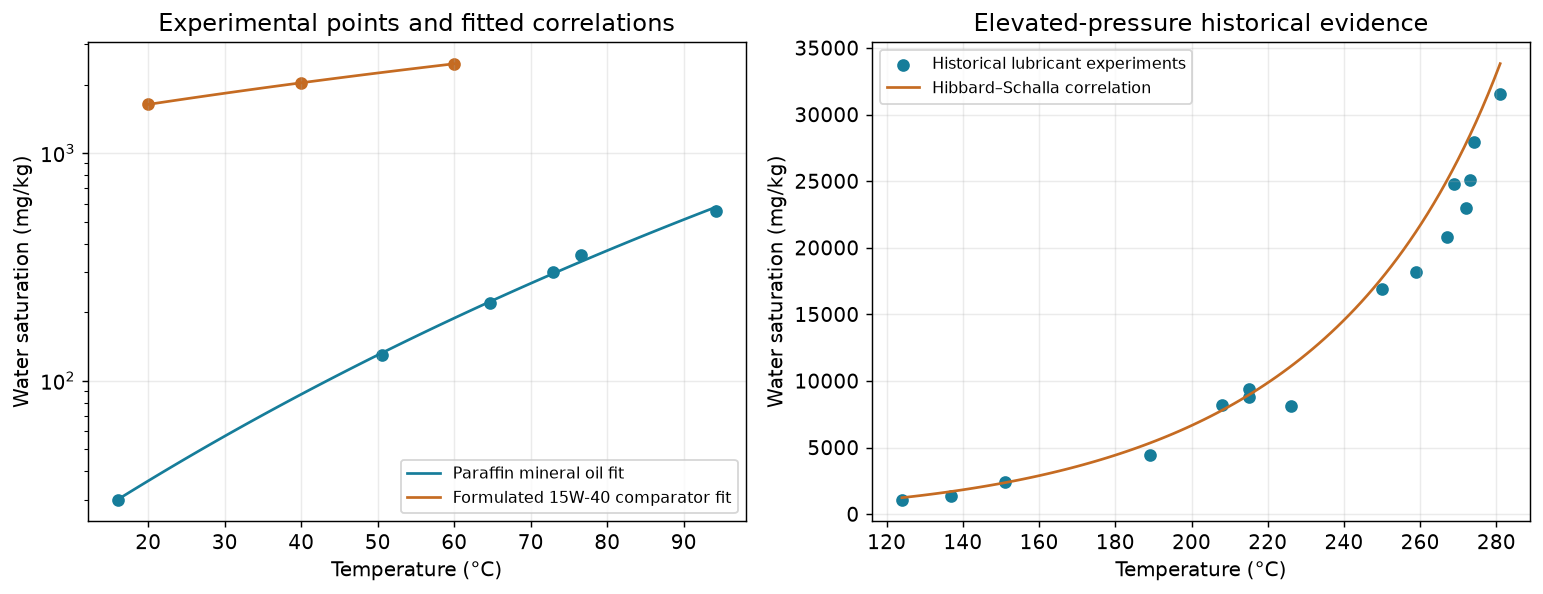

In [5]:
def fit_arrhenius(data):
    inverse_temperature = 1.0 / (data.temperature_C.to_numpy() + 273.15)
    slope, intercept = np.polyfit(inverse_temperature, np.log10(data.water_ppmw), 1)
    return float(intercept), float(-slope)

def empirical_ppmw(temperature_C, coefficients):
    intercept, inverse_temperature_slope = coefficients
    return 10.0 ** (intercept - inverse_temperature_slope / (temperature_C + 273.15))

def hibbard_ppmw(temperature_C, hc_mass_ratio=0.151, oil_MW=425.0):
    temperature_K = np.asarray(temperature_C) + 273.15
    mole_percent = 10.0 ** (-(4200.0 * hc_mass_ratio + 1050.0)
                           * (1.0 / temperature_K - 0.0016) + 2.0)
    mole_fraction = mole_percent / 100.0
    return 1e6 * mole_fraction * MW_WATER / (
        mole_fraction * MW_WATER + (1.0 - mole_fraction) * oil_MW
    )

paraffin_fit = fit_arrhenius(paraffin_exp)
engine_fit = fit_arrhenius(engine_exp)
historical_exp['Hibbard_ppmw'] = hibbard_ppmw(historical_exp.temperature_C)
historical_exp['relative_error_percent'] = 100.0 * (
    historical_exp.Hibbard_ppmw / historical_exp.water_ppmw - 1.0
)
print('Fitted A, B (K):', {'paraffin': paraffin_fit, 'formulated comparator': engine_fit})
display(historical_exp[[
    'temperature_C', 'water_ppmw', 'Hibbard_ppmw', 'relative_error_percent',
]].round(2))
print('Historical correlation mass-basis MAPE (%):',
      historical_exp.relative_error_percent.abs().mean())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
for data, fit, label, color in [
    (paraffin_exp, paraffin_fit, 'Paraffin mineral oil', '#167d9a'),
    (engine_exp, engine_fit, 'Formulated 15W-40 comparator', '#c56b22'),
]:
    grid = np.linspace(data.temperature_C.min(), data.temperature_C.max(), 100)
    axes[0].plot(grid, empirical_ppmw(grid, fit), color=color, label=label + ' fit')
    axes[0].scatter(data.temperature_C, data.water_ppmw, color=color, marker='o')
axes[0].set_yscale('log')
axes[0].set(xlabel='Temperature (°C)', ylabel='Water saturation (mg/kg)',
            title='Experimental points and fitted correlations')
axes[0].legend(fontsize=9)
axes[1].scatter(historical_exp.temperature_C, historical_exp.water_ppmw,
                label='Historical lubricant experiments', color='#167d9a')
high_grid = np.linspace(124.0, 281.0, 100)
axes[1].plot(high_grid, hibbard_ppmw(high_grid), label='Hibbard–Schalla correlation',
             color='#c56b22')
axes[1].set(xlabel='Temperature (°C)', ylabel='Water saturation (mg/kg)',
            title='Elevated-pressure historical evidence')
axes[1].legend(fontsize=9)
fig.tight_layout()
save_figure('01_experimental_evidence.png')

## 5. NeqSim equilibrium calculation and oil representations
CPA treats water association explicitly; SRK provides a cubic-EOS comparator. Each oil is
represented by a TBP pseudo-component with mean molecular weight and reference density.
NeqSim estimates its critical properties. This does not recover aromaticity, naphthenic ring
content or additives from density alone. The cases below are **assumed screening oils**, not
validated branded products or an assignment to ISO viscosity grades.

One mole of oil and excess water are flashed at fixed temperature and pressure with multiphase
checking. Saturation is read only when oil and aqueous phases coexist. A component ledger and
water fugacity equality check qualify every reported flash:

$$x_w^{o}\phi_w^{o}P=x_w^{a}\phi_w^{a}P$$

$x$ is mole fraction, $\phi$ is fugacity coefficient, $P$ is absolute pressure in bar;
$o$ and $a$ denote oil and aqueous phases. No emulsion model is included.

In [6]:
oils = pd.DataFrame([
    {'oil': 'Light paraffinic proxy', 'MW_kg_mol': 0.250, 'density_g_cm3': 0.850},
    {'oil': 'Medium paraffinic proxy', 'MW_kg_mol': 0.300, 'density_g_cm3': 0.870},
    {'oil': 'Heavy mineral proxy', 'MW_kg_mol': 0.425, 'density_g_cm3': 141.5 / 160.8},
    {'oil': 'Naphthenic-density proxy', 'MW_kg_mol': 0.300, 'density_g_cm3': 0.920},
])
display(oils)

def water_saturation(oil, temperature_C, pressure_bara=1.01325,
                     model='CPA', water_moles=1.0, kij=None):
    system_class = CPA if model == 'CPA' else SRK
    fluid = system_class(float(temperature_C + 273.15), float(pressure_bara))
    fluid.addTBPfraction('lube', 1.0, float(oil['MW_kg_mol']),
                         float(oil['density_g_cm3']))
    fluid.addComponent('water', float(water_moles))
    fluid.setMixingRule(10 if model == 'CPA' else 2)
    fluid.setMultiPhaseCheck(True)
    if kij is not None:
        for phase_index in range(fluid.getMaxNumberOfPhases()):
            fluid.getPhase(phase_index).getMixingRule().setBinaryInteractionParameter(
                0, 1, float(kij),
            )
    Operations(fluid).TPflash()
    fluid.init(3)
    assert fluid.hasPhaseType('oil') and fluid.hasPhaseType('aqueous')
    oil_phase = fluid.getPhase('oil')
    aqueous_phase = fluid.getPhase('aqueous')
    oil_water = oil_phase.getComponent('water')
    aqueous_water = aqueous_phase.getComponent('water')
    oil_fugacity = oil_water.getx() * oil_water.getFugacityCoefficient() * pressure_bara
    aqueous_fugacity = (
        aqueous_water.getx() * aqueous_water.getFugacityCoefficient() * pressure_bara
    )
    fugacity_residual = abs(oil_fugacity / aqueous_fugacity - 1.0)
    ledger_errors = []
    for component_index in range(fluid.getNumberOfComponents()):
        recovered = sum(
            fluid.getPhase(p).getComponent(component_index).getNumberOfMolesInPhase()
            for p in range(fluid.getNumberOfPhases())
        )
        feed = 1.0 if component_index == 0 else water_moles
        ledger_errors.append(abs(recovered / feed - 1.0))
    ppmw = 1e6 * oil_phase.getWtFrac('water')
    assert 0.0 < ppmw < 1e6
    assert max(ledger_errors) < 1e-7
    assert fugacity_residual < 1e-5
    return {
        'oil': oil['oil'], 'temperature_C': float(temperature_C),
        'pressure_bara': float(pressure_bara), 'model': model, 'water_ppmw': ppmw,
        'fugacity_relative_residual': fugacity_residual,
        'max_component_relative_residual': max(ledger_errors),
    }

screening_rows = []
for _, oil in oils.iterrows():
    for model in ['CPA', 'SRK']:
        for temperature_C in np.linspace(20.0, 95.0, 16):
            screening_rows.append(water_saturation(oil, temperature_C, model=model))
screening = pd.DataFrame(screening_rows)
display(screening[screening.temperature_C.isin([20.0, 50.0, 80.0, 95.0])][[
    'oil', 'model', 'temperature_C', 'water_ppmw',
]].round(2))
print('Maximum fugacity residual:', screening.fugacity_relative_residual.max())
print('Maximum component ledger residual:', screening.max_component_relative_residual.max())

Maximum fugacity residual: 3.9390712913700554e-13
Maximum component ledger residual: 8.815170815523743e-14


,oil,MW_kg_mol,density_g_cm3
0,Light paraffinic proxy,0.250,0.850000
1,Medium paraffinic proxy,0.300,0.870000
2,Heavy mineral proxy,0.425,0.879975
3,Naphthenic-density proxy,0.300,0.920000


,oil,model,temperature_C,water_ppmw
0,Light paraffinic proxy,CPA,20.0,38.90
6,Light paraffinic proxy,CPA,50.0,142.31
12,Light paraffinic proxy,CPA,80.0,419.75
15,Light paraffinic proxy,CPA,95.0,677.25
16,Light paraffinic proxy,SRK,20.0,241.87
22,Light paraffinic proxy,SRK,50.0,701.36
28,Light paraffinic proxy,SRK,80.0,1687.97
31,Light paraffinic proxy,SRK,95.0,2484.34
32,Medium paraffinic proxy,CPA,20.0,36.15
38,Medium paraffinic proxy,CPA,50.0,129.29


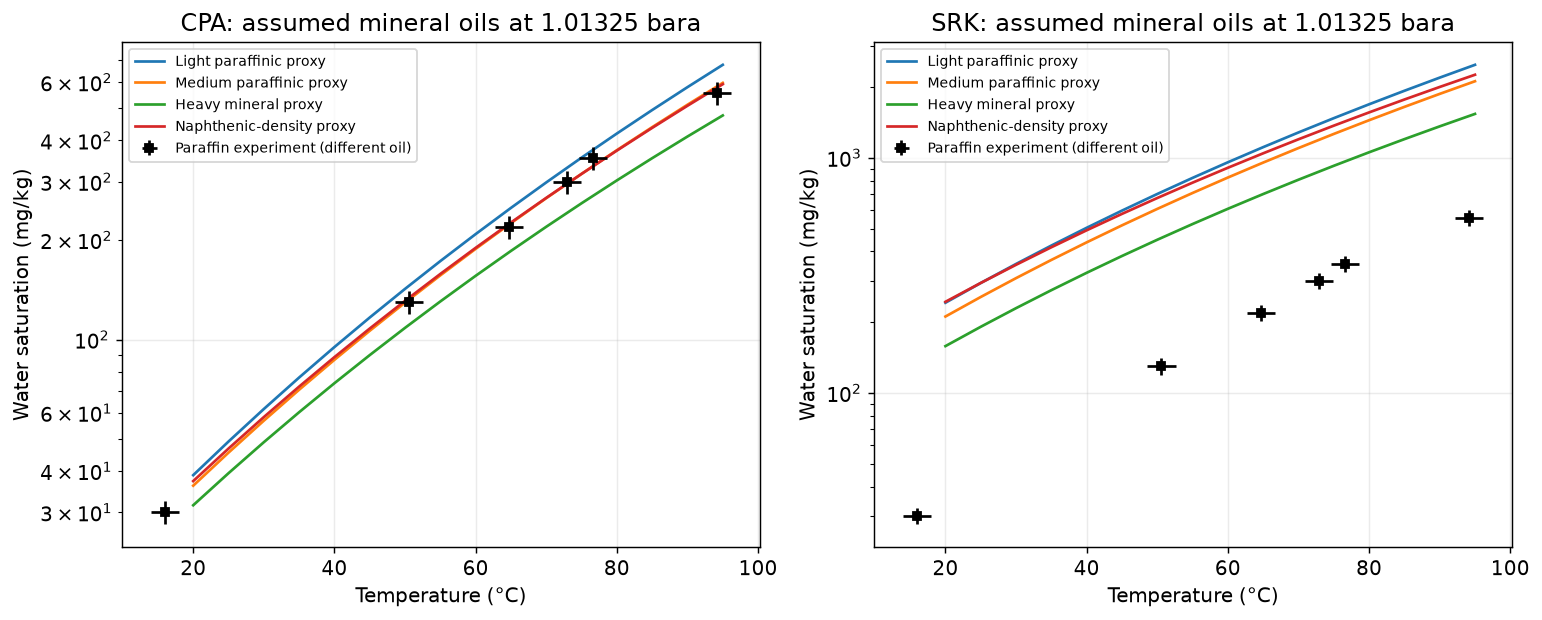

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.9))
for model, axis in zip(['CPA', 'SRK'], axes):
    subset = screening[screening.model == model]
    for name, group in subset.groupby('oil', sort=False):
        axis.plot(group.temperature_C, group.water_ppmw, label=name)
    axis.errorbar(paraffin_exp.temperature_C, paraffin_exp.water_ppmw,
                   yerr=paraffin_exp.reading_envelope_ppmw,
                   xerr=paraffin_exp.temperature_envelope_C,
                   fmt='ks', markersize=4, label='Paraffin experiment (different oil)')
    axis.set_yscale('log')
    axis.set(xlabel='Temperature (°C)', ylabel='Water saturation (mg/kg)',
             title=f'{model}: assumed mineral oils at 1.01325 bara')
    axis.legend(fontsize=8)
fig.tight_layout()
save_figure('02_neqsim_oil_comparison.png')

## 6. Calibration on one point and held-out comparison
The paraffin comparison assumes nominal atmospheric pressure because the reproduced figure
does not give a precise pressure. For the paraffin experimental oil, MW = 300 g/mol and density = 0.870 g/cm³ are **assumed**.
Compare default CPA and SRK at every measured temperature. Then calibrate one constant
water–oil interaction parameter to the 50.6 °C point only. Report the other five points as
held-out comparisons conditional on the assumed characterization. The fit absorbs unknown
composition and reading error; it is not a transferable mineral-oil parameter.

Fitted constant CPA water–oil kij: -0.16345785805764546


,model,temperature_C,experiment_ppmw,prediction_ppmw,error_percent,role
0,CPA default,16.0,30.0,29.901,-0.328,held-out
1,SRK default,16.0,30.0,180.438,501.459,held-out
2,CPA one-point fit,16.0,30.0,29.287,-2.376,held-out
3,CPA default,50.6,130.0,132.314,1.780,calibration
4,SRK default,50.6,130.0,617.688,375.145,calibration
5,CPA one-point fit,50.6,130.0,130.000,-0.000,calibration
6,CPA default,64.7,219.0,222.507,1.601,held-out
7,SRK default,64.7,219.0,945.735,331.842,held-out
8,CPA one-point fit,64.7,219.0,218.838,-0.074,held-out
9,CPA default,72.9,300.0,295.404,-1.532,held-out


,MAPE_percent,maximum_absolute_error_percent
model,,
CPA default,2.87,5.83
CPA one-point fit,3.27,7.31
SRK default,335.18,501.46


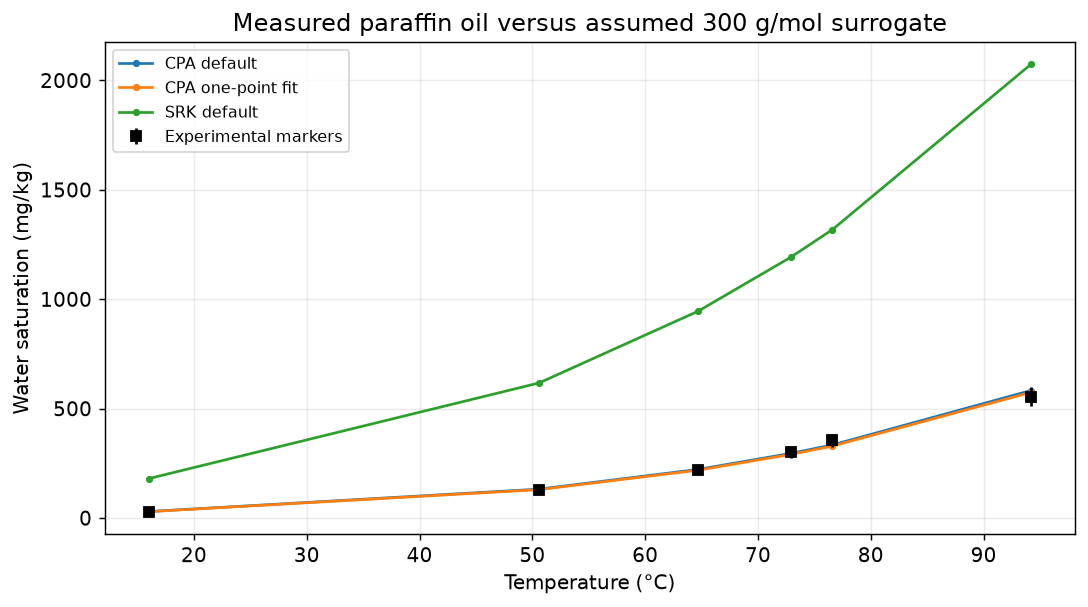

In [8]:
paraffin_proxy = oils.iloc[1].to_dict()
calibration_temperature = 50.6
calibration_target = 130.0

def calibration_residual(kij):
    result = water_saturation(paraffin_proxy, calibration_temperature, kij=kij)
    return np.log(result['water_ppmw'] / calibration_target)

fitted_kij = brentq(calibration_residual, -0.4, 0.4, xtol=1e-8)
comparison_rows = []
for _, measurement in paraffin_exp.iterrows():
    for label, model, kij in [
        ('CPA default', 'CPA', None),
        ('SRK default', 'SRK', None),
        ('CPA one-point fit', 'CPA', fitted_kij),
    ]:
        result = water_saturation(paraffin_proxy, measurement.temperature_C,
                                  model=model, kij=kij)
        prediction = result['water_ppmw']
        comparison_rows.append({
            'model': label, 'temperature_C': measurement.temperature_C,
            'experiment_ppmw': measurement.water_ppmw, 'prediction_ppmw': prediction,
            'error_percent': 100.0 * (prediction / measurement.water_ppmw - 1.0),
            'role': ('calibration' if measurement.temperature_C == 50.6 else 'held-out'),
        })
comparison = pd.DataFrame(comparison_rows)
print('Fitted constant CPA water–oil kij:', fitted_kij)
display(comparison.round(3))
heldout_metrics = comparison[comparison.role == 'held-out'].groupby('model').agg(
    MAPE_percent=('error_percent', lambda values: values.abs().mean()),
    maximum_absolute_error_percent=('error_percent', lambda values: values.abs().max()),
)
display(heldout_metrics.round(2))

fig, axis = plt.subplots(figsize=(8.5, 4.8))
for name, group in comparison.groupby('model'):
    axis.plot(group.temperature_C, group.prediction_ppmw, marker='.', label=name)
axis.errorbar(paraffin_exp.temperature_C, paraffin_exp.water_ppmw,
               yerr=paraffin_exp.reading_envelope_ppmw, fmt='ks', label='Experimental markers')
axis.set(xlabel='Temperature (°C)', ylabel='Water saturation (mg/kg)',
         title='Measured paraffin oil versus assumed 300 g/mol surrogate')
axis.legend(fontsize=9)
fig.tight_layout()
save_figure('03_calibration_and_holdout.png')

## 7. Pressure, characterization and excess-water sensitivity
The pressure sweep maintains contact with liquid water and applies pressure mechanically.
It does not represent water fugacity in a humid gas, dissolved compressor gas, or a gas-bearing
lubricant. Characterization changes are scenarios, not statistical confidence intervals.
Changing the amount of excess water should not change a binary liquid–liquid saturation result.

Excess-water inventory independence: passed; ppmw = [188.0034642  188.00346419 188.00346419]


pressure_bara,1.01325,10.00000,50.00000,100.00000
oil,,,,
Heavy mineral proxy,155.86,154.73,149.94,144.45
Light paraffinic proxy,208.38,206.62,199.23,190.90
Medium paraffinic proxy,188.00,186.52,180.25,173.14
Naphthenic-density proxy,189.36,188.08,182.64,176.40


density_g_cm3,0.85,0.87,0.89
MW_g_mol,,,
250.0,145.70,145.97,146.30
300.0,131.77,132.31,132.92
350.0,121.20,121.95,122.77


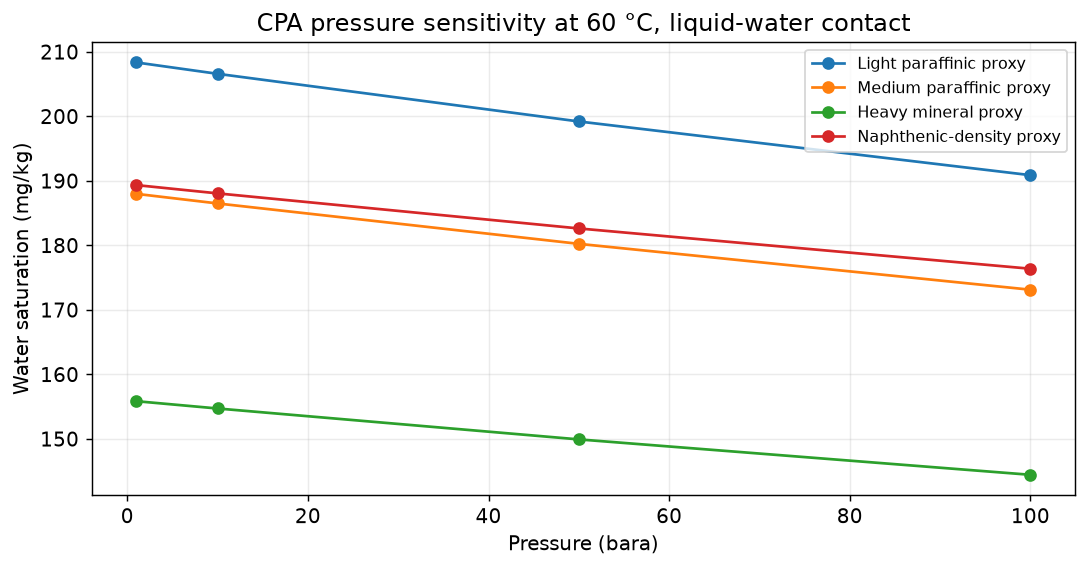

In [9]:
pressure_rows = []
for _, oil in oils.iterrows():
    for pressure_bara in [1.01325, 10.0, 50.0, 100.0]:
        pressure_rows.append(water_saturation(oil, 60.0, pressure_bara))
pressure_results = pd.DataFrame(pressure_rows)
display(pressure_results.pivot(index='oil', columns='pressure_bara',
                               values='water_ppmw').round(2))

sensitivity_rows = []
for molecular_weight in [0.250, 0.300, 0.350]:
    for density in [0.850, 0.870, 0.890]:
        altered_oil = {'oil': 'Paraffin characterization scenario',
                       'MW_kg_mol': molecular_weight, 'density_g_cm3': density}
        result = water_saturation(altered_oil, 50.6)
        sensitivity_rows.append({
            'MW_g_mol': molecular_weight * 1000, 'density_g_cm3': density,
            'water_ppmw': result['water_ppmw'],
        })
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.pivot(index='MW_g_mol', columns='density_g_cm3',
                          values='water_ppmw').round(2))

inventory_results = [water_saturation(paraffin_proxy, 60.0, water_moles=amount)
                     for amount in [0.2, 1.0, 2.0]]
concentrations = np.array([result['water_ppmw'] for result in inventory_results])
assert np.ptp(concentrations) / concentrations.mean() < 1e-5
print('Excess-water inventory independence: passed; ppmw =', concentrations)

fig, axis = plt.subplots(figsize=(8.5, 4.5))
for name, group in pressure_results.groupby('oil', sort=False):
    axis.plot(group.pressure_bara, group.water_ppmw, marker='o', label=name)
axis.set(xlabel='Pressure (bara)', ylabel='Water saturation (mg/kg)',
         title='CPA pressure sensitivity at 60 °C, liquid-water contact')
axis.legend(fontsize=9)
fig.tight_layout()
save_figure('04_pressure_sensitivity.png')

## 8. Cooling a lubricant reservoir
Take 1,000 kg of dry oil, initially saturated at 80 °C, and cool to 20 °C in a closed reservoir.
For water mass fraction $w$, the water-to-dry-oil ratio is $w/(1-w)$. The potential separated
water is calculated from the change in that ratio:

$$m_{w,\mathrm{released}}=m_{o,\mathrm{dry}}\max\left(0,\frac{w_{80}}{1-w_{80}}-\frac{w_{20}}{1-w_{20}}\right)$$

Water mass is in kg. This is a saturation-capacity balance; it neglects oil dissolved in water,
headspace water, oil aging and additive loss. It does not predict settling time or droplet sizes.
The formulated-oil comparator is only interpolated within its 20–60 °C data range.

,oil,80C_ppmw,20C_ppmw,released_water_kg
0,Light paraffinic proxy,419.7486,38.8989,0.3810
1,Medium paraffinic proxy,373.7355,36.1518,0.3377
2,Heavy mineral proxy,302.8300,31.5458,0.2714
3,Naphthenic-density proxy,372.7374,37.3218,0.3356


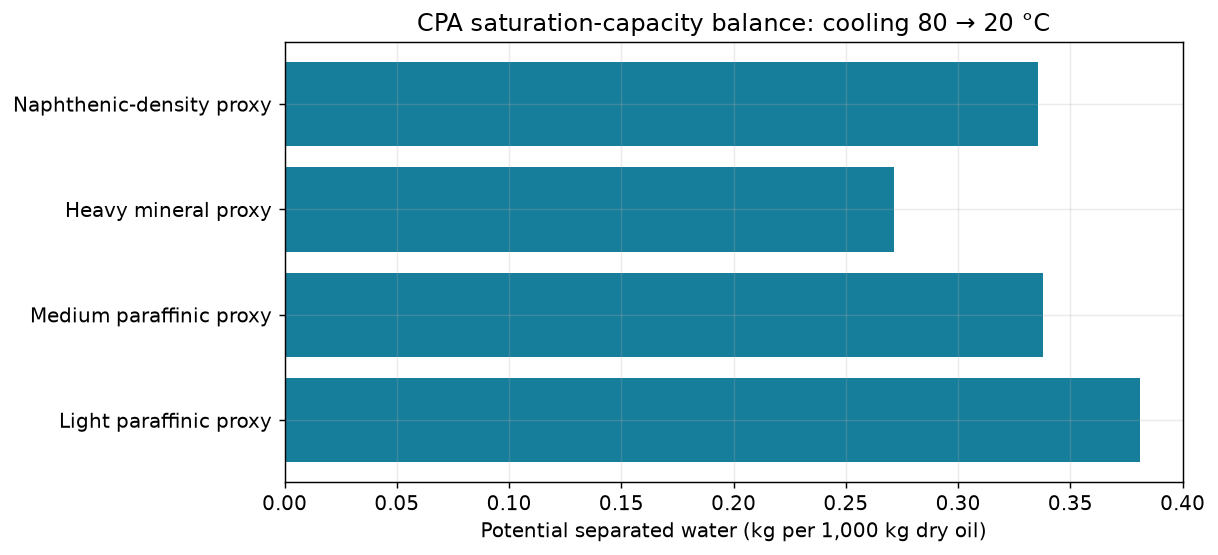

In [10]:
cooling_rows = []
for _, oil in oils.iterrows():
    hot_ppmw = water_saturation(oil, 80.0)['water_ppmw']
    cold_ppmw = water_saturation(oil, 20.0)['water_ppmw']
    hot_fraction = hot_ppmw / 1e6
    cold_fraction = cold_ppmw / 1e6
    released_kg = 1000.0 * max(
        0.0, hot_fraction / (1.0 - hot_fraction) - cold_fraction / (1.0 - cold_fraction),
    )
    cooling_rows.append({'oil': oil['oil'], '80C_ppmw': hot_ppmw,
                         '20C_ppmw': cold_ppmw, 'released_water_kg': released_kg})
cooling = pd.DataFrame(cooling_rows)
display(cooling.round(4))
fig, axis = plt.subplots(figsize=(9.5, 4.4))
axis.barh(cooling.oil, cooling.released_water_kg, color='#167d9a')
axis.set(xlabel='Potential separated water (kg per 1,000 kg dry oil)',
         title='CPA saturation-capacity balance: cooling 80 → 20 °C')
fig.tight_layout()
save_figure('05_cooling_water_release.png')

## 9. Add your own lubricant measurements
For each oil, measure density, mean MW or a defensible distillation characterization, and
stabilized dissolved-water content at several temperatures. Record product, batch, base-oil
family, additive content, age, pressure, sampling method and KF uncertainty. Avoid droplets in
samples and check both heating and cooling paths. A visually clear oil need not prove exclusively
molecularly dissolved water. More than one equilibrium temperature is needed to test a fitted EOS.

The helper below validates a CSV schema and fits an empirical saturation curve. It is demonstrated
on the sourced paraffin data; replace the path with your own CSV to reuse it. It does not silently
change NeqSim database parameters.

In [11]:
paraffin_exp[['temperature_C', 'water_ppmw']].to_csv(
    results_dir / 'experimental_input_example.csv', index=False,
)

def load_experimental_csv(path):
    data = pd.read_csv(path)
    required = ['temperature_C', 'water_ppmw']
    assert all(name in data.columns for name in required)
    assert len(data) >= 3 and data.temperature_C.nunique() >= 3
    assert np.isfinite(data[required].to_numpy()).all()
    assert (data.water_ppmw > 0).all() and (data.water_ppmw < 1e6).all()
    assert (data.temperature_C > 0).all()
    return data.sort_values('temperature_C')

loaded_measurements = load_experimental_csv(results_dir / 'experimental_input_example.csv')
print('Reusable CSV input fit (A, B):', fit_arrhenius(loaded_measurements))
for name, data in {
    'paraffin_experiments': paraffin_exp,
    'historical_lubricant_experiments': historical_exp,
    'formulated_oil_stabilized_readings': engine_readings,
    'formulated_oil_means': engine_exp,
    'oil_characterizations': oils,
    'neqsim_screening': screening,
    'calibration_comparison': comparison,
    'heldout_metrics': heldout_metrics.reset_index(),
    'pressure_sensitivity': pressure_results,
    'characterization_sensitivity': sensitivity,
    'cooling_water_release': cooling,
}.items():
    data.to_csv(results_dir / f'{name}.csv', index=False)
print('CSV tables and five figures exported to:', results_dir.resolve())

Reusable CSV input fit (A, B): (7.515228856509262, 1745.8997685287043)
CSV tables and five figures exported to: /workspace/scratch/6fd28e4fcacb/water_oil_results


## 10. Engineering conclusions and qualification limits

Read the numerical summary below together with the evidence labels. Differences between
experimental oils and assumed pseudo-components are expected. A density-derived naphthenic
proxy is not a chemically explicit naphthenic or aromatic model. CPA's water association does
not model detergent micelles, emulsions or dissolved process gas.

The one-point CPA fit does not improve held-out error here; retain default CPA unless
additional measured data justify calibration. The study reports thermodynamic consistency
and held-out paraffin comparisons. Agreement is
conditional on assumed characterization and coarse digitization. It does not qualify a named
hydraulic, turbine, compressor, gear or engine oil. Do not interpret solubility as an acceptable
water-contamination limit; consult the equipment and oil supplier's specification.

**Validation:** clean sequential execution; source/JAR identity; positive phase-specific mass
fractions; aqueous/oil coexistence; fugacity and component ledgers; excess-water independence;
calibration/held-out split; rendered HTML/MathJax and inspection of all five figures and tables.

**Next experiments:** obtain an additive-free paraffinic and naphthenic oil with measured MW,
density and carbon-type distribution, then test multiple temperatures and actual compressor-gas
pressures. Compare additive-free and formulated versions before introducing effective parameters.

**Exercises:** change the oil MW at constant density; compare a density change at constant MW;
fit on a different point and examine held-out errors; repeat the cooling case with measured oil
characterization and your own saturation curve.

In [12]:
medium_20 = water_saturation(paraffin_proxy, 20.0)['water_ppmw']
medium_80 = water_saturation(paraffin_proxy, 80.0)['water_ppmw']
engine_20 = float(engine_exp.loc[engine_exp.temperature_C == 20.0, 'water_ppmw'].iloc[0])
summary = f"""
**Executed findings**

- Medium paraffinic CPA proxy: **{medium_20:.1f} mg/kg at 20 °C** and
  **{medium_80:.1f} mg/kg at 80 °C**, at 1.01325 bara.
- Formulated 15W-40 experimental comparator: **{engine_20:.1f} mg/kg at 20 °C**;
  this is a different formulation and an operational KF saturation measurement.
- Default CPA held-out paraffin MAPE: **{heldout_metrics.loc['CPA default', 'MAPE_percent']:.1f}%**.
- One-point-calibrated CPA held-out MAPE:
  **{heldout_metrics.loc['CPA one-point fit', 'MAPE_percent']:.1f}%**.
- Largest equilibrium fugacity residual: **{screening.fugacity_relative_residual.max():.2e}**.
- Cooling-water release across assumed oils: **{cooling.released_water_kg.min():.3f}–
  {cooling.released_water_kg.max():.3f} kg per 1,000 kg dry oil**.
"""
display(Markdown(summary))


**Executed findings**

- Medium paraffinic CPA proxy: **36.2 mg/kg at 20 °C** and
  **373.7 mg/kg at 80 °C**, at 1.01325 bara.
- Formulated 15W-40 experimental comparator: **1637.8 mg/kg at 20 °C**;
  this is a different formulation and an operational KF saturation measurement.
- Default CPA held-out paraffin MAPE: **2.9%**.
- One-point-calibrated CPA held-out MAPE:
  **3.3%**.
- Largest equilibrium fugacity residual: **3.94e-13**.
- Cooling-water release across assumed oils: **0.271–
  0.381 kg per 1,000 kg dry oil**.
